In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Load the cleaned data saved on Day 1 (fast: parquet, not the big CSV)
df = pd.read_parquet("../data/interim/complaints_text.parquet")

In [3]:
# Your turn: print the shape
df.shape

(904207, 4)

In [4]:
# Your turn: print the dtypes
df.dtypes

Date received                   datetime64[us]
Product                                    str
Consumer complaint narrative               str
Complaint ID                             int64
dtype: object

[Text(0, 0, '607,924'),
 Text(0, 0, '75,948'),
 Text(0, 0, '66,984'),
 Text(0, 0, '38,269'),
 Text(0, 0, '35,797'),
 Text(0, 0, '30,572'),
 Text(0, 0, '13,467'),
 Text(0, 0, '9,415'),
 Text(0, 0, '8,574'),
 Text(0, 0, '7,194'),
 Text(0, 0, '4,460'),
 Text(0, 0, '3,151'),
 Text(0, 0, '1,502'),
 Text(0, 0, '950')]

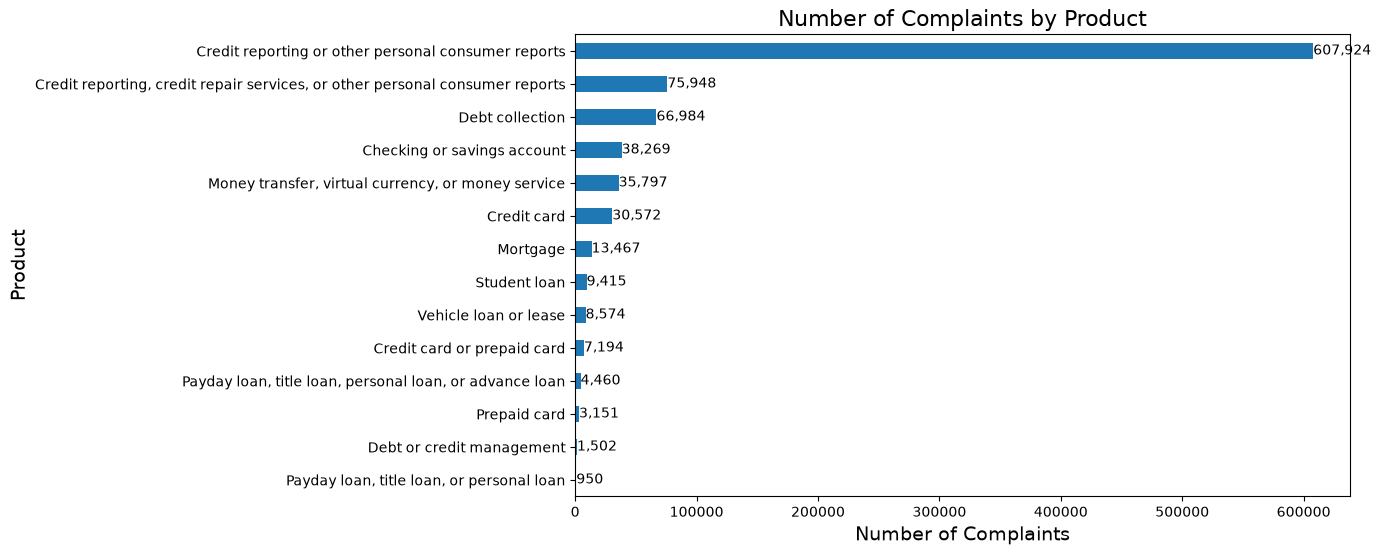

In [5]:
#Bar Chart
counts = df["Product"].value_counts()
ax= counts.plot(kind="barh", figsize=(10, 6))
ax.set_title("Number of Complaints by Product", fontsize=16)
ax.set_ylabel("Product", fontsize=14)
ax.set_xlabel("Number of Complaints", fontsize=14)
ax.invert_yaxis()
ax.bar_label(ax.containers[0], fmt="{:,.0f}")



In [6]:
#Adding Month column
df['month'] = df['Date received'].dt.to_period('M')
print(df['month'].head(5))
print(df['month'].nunique())

0    2025-05
1    2024-05
2    2025-06
3    2025-05
4    2024-11
Name: month, dtype: period[M]
30


month
2023-01    12433
2023-02    10762
2023-03    11634
Freq: M, Name: count, dtype: int64
month
2025-04    56132
2025-05    57053
2025-06    48219
Freq: M, Name: count, dtype: int64


Text(0.5, 0, 'Month')

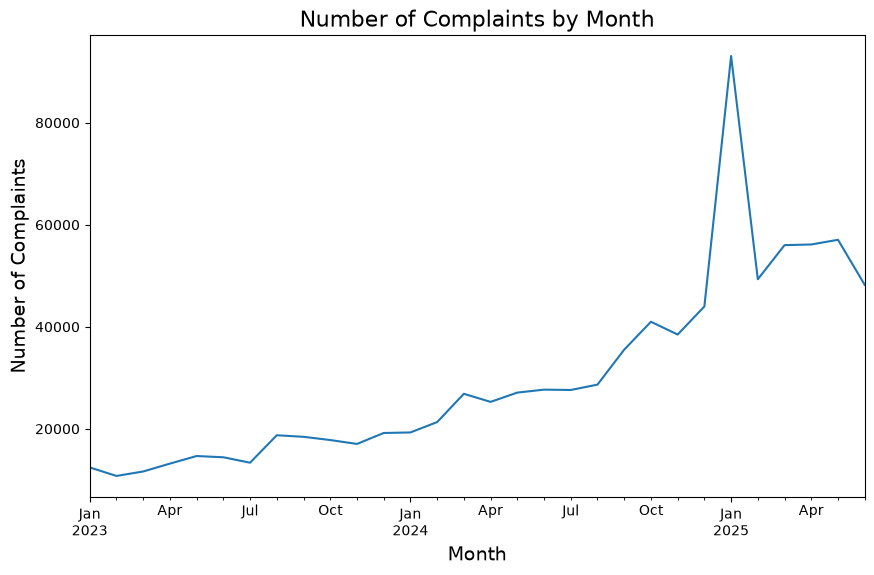

In [7]:
monthly = df['month'].value_counts().sort_index()
print(monthly.head(3))
print(monthly.tail(3))

ax = monthly.plot(kind="line", figsize=(10, 6))
ax.set_title("Number of Complaints by Month", fontsize=16)
ax.set_ylabel("Number of Complaints", fontsize=14)
ax.set_xlabel("Month", fontsize=14)

In [8]:
product_dates = df.groupby(['Product'])['month'].agg(['min', 'max', 'count'])
product_dates = product_dates.sort_values('min')
product_dates

,min,max,count
Product,,,
Checking or savings account,2023-01,2025-06,38269
Credit card or prepaid card,2023-01,2023-08,7194
Debt collection,2023-01,2025-06,66984
"Credit reporting, credit repair services, or other personal consumer reports",2023-01,2023-08,75948
"Money transfer, virtual currency, or money service",2023-01,2025-06,35797
Vehicle loan or lease,2023-01,2025-06,8574
"Payday loan, title loan, or personal loan",2023-01,2023-08,950
Mortgage,2023-01,2025-06,13467
Student loan,2023-01,2025-06,9415


## Day 2 observations

1. **Class imbalance:** "Credit reporting or other personal consumer reports" is 607,924 of 904,207 rows (67.2%), while the smallest class has only 950 (0.1%), about 640× smaller. Accuracy alone would be misleading, so we'll use macro-F1 and per-class metrics.

2. **Volume over time:** Monthly complaints grew about 4.6× from 12,433 (Jan 2023) to 57,053 (May 2025), with a one-off spike of 93,090 in Jan 2025 (almost double its neighbours). June 2025 drops about 15% to 48,219, possibly incomplete data, so be careful using the latest month as the test set.

3. **Category change on 25 Aug 2023:** Three product names end on 24–25 Aug 2023 and five new names start then. That's two clean renames (credit reporting, payday loans) and two splits (credit/prepaid cards, and possibly credit repair → "Debt or credit management"). Labels must be mapped before training (Day 4).


In [9]:
df["word_count"] = df["Consumer complaint narrative"].str.split().str.len()
print(df['word_count'].head(5))
print(df['word_count'].isna().sum())

0    155
1    157
2     60
3     39
4    102
Name: word_count, dtype: int64
0


In [11]:
print(df['word_count'].quantile([0.50,0.9,0.95,0.99,1.0]))
print(df['word_count'].describe())

0.50     112.0
0.90     349.0
0.95     482.0
0.99     955.0
1.00    6469.0
Name: word_count, dtype: float64
count    904207.000000
mean        170.122052
std         216.554661
min           1.000000
25%          58.000000
50%         112.000000
75%         205.000000
max        6469.000000
Name: word_count, dtype: float64


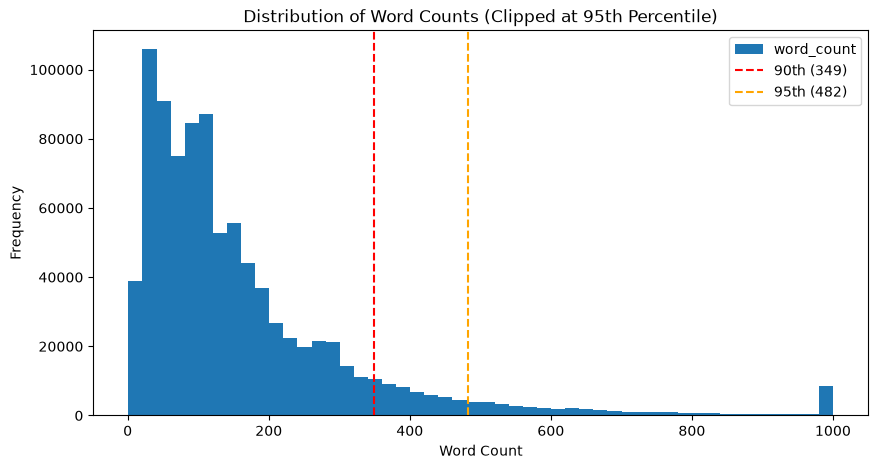

In [13]:
ax = df["word_count"].clip(upper=1000).plot(kind="hist", bins=50, figsize=(10, 5))
ax.axvline(349, color="red", linestyle="--", label="90th (349)")
ax.axvline(482, color="orange", linestyle="--", label="95th (482)")
ax.set_title("Distribution of Word Counts (Clipped at 95th Percentile)")
ax.set_xlabel("Word Count")
ax.set_ylabel("Frequency")
ax.legend()

In [14]:
pct = df['Consumer complaint narrative'].str.contains('XXXX').mean()*100
print(f"{pct:.1f}% of narratives contain XXXX")


62.3% of narratives contain XXXX


In [15]:
narr = df["Consumer complaint narrative"]

n_dupes = narr.duplicated().sum()
print(f"Exact duplicates: {n_dupes:,}")


top5 = narr.value_counts().head(5)
for text,count in top5.items():
    print(f"{count:,} occurrences of: {text[:100]}...")

Exact duplicates: 339,262
10,812 occurrences of: In accordance with the Fair Credit Reporting act. The List of accounts below has violated my federal...
9,019 occurrences of: My credit reports are inaccurate. These inaccuracies are causing creditors to deny me credit. You ha...
6,423 occurrences of: Upon reviewing my credit report, I have identified inaccurate accounts that need reporting and corre...
5,254 occurrences of: I have not supplied proof under the doctrine of estoppel by silence, Engelhardt V. Gravens ( MO ) 28...
4,703 occurrences of: I am writing to have the following information removed from my credit file, the items that I need de...


In [16]:
n_products = df.groupby('Consumer complaint narrative')['Product'].nunique()
conflict = n_products>1
print(f"Texts with conflicting labels: {conflict.sum():,}")
top3 = n_products[conflict].sort_values(ascending=False).head(3)
for text, n in top3.items():
    labels = df.loc[df["Consumer complaint narrative"] == text, "Product"].unique()
    print(n, "products |", text[:100], "|", list(labels))

Texts with conflicting labels: 1,558
5 products | See the attached documents. I want the bureau to start the investigation on these accounts that I am | ['Credit reporting, credit repair services, or other personal consumer reports', 'Credit card', 'Credit card or prepaid card', 'Credit reporting or other personal consumer reports', 'Vehicle loan or lease']
5 products | This account has inaccurate reporting. The company has failed to properly investigate. These account | ['Debt collection', 'Credit card', 'Payday loan, title loan, personal loan, or advance loan', 'Credit reporting or other personal consumer reports', 'Vehicle loan or lease']
5 products | 15 U.S. Code $ 1681c-2 a consumer reporting agency shall block the reporting of any information in t | ['Credit reporting, credit repair services, or other personal consumer reports', 'Credit reporting or other personal consumer reports', 'Vehicle loan or lease', 'Credit card or prepaid card', 'Debt collection']


In [17]:
df["is_dup"] = df["Consumer complaint narrative"].duplicated(keep=False)


In [18]:
for m in ["2024-12", "2025-01"]:
    month_df = df[df["month"] == pd.Period(m)]
    print("=====", m, "| rows:", len(month_df))
    print(month_df["Product"].value_counts(normalize=True).head(3))
    print("Duplicate share:", month_df["is_dup"].mean())

===== 2024-12 | rows: 43981
Product
Credit reporting or other personal consumer reports    0.795844
Debt collection                                        0.074873
Credit card                                            0.035379
Name: proportion, dtype: float64
Duplicate share: 0.43828016643550627
===== 2025-01 | rows: 93090
Product
Credit reporting or other personal consumer reports    0.576893
Money transfer, virtual currency, or money service     0.239886
Checking or savings account                            0.079160
Name: proportion, dtype: float64
Duplicate share: 0.43014287248898914
